In [40]:
import pandas as pd

df = pd.read_csv(
    '/content/issp_onet_baseline_us.csv',
    dtype={'ONET_SOC_CODE': 'string'}
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (2040, 44)


,ONET_SOC_CODE,module_year,job_satisfaction,age,sex,marital_status,educ_years,educ_level,household_income_group,hours_worked_weekly,employment_status_current,union_member,household_size,child_in_household,urban_rural,imp_job_security,imp_income,imp_advancement,imp_interesting,imp_independence,imp_help_others,imp_useful_society,imp_decide_hours,actual_job_secure,actual_income_high,actual_advancement_high,actual_job_interesting,actual_work_independently,actual_help_others,actual_useful_society,onet_job_zone,career_interest_types_OI_artistic_value,career_interest_types_OI_conventional_value,career_interest_types_OI_enterprising_value,career_interest_types_OI_investigative_value,career_interest_types_OI_realistic_value,career_interest_types_OI_social_value,fit_gap_security,fit_gap_income,fit_gap_advancement,fit_gap_interesting,fit_gap_independence,fit_gap_help_others,fit_gap_useful_society
0,25-2056.00,1997.0,5.0,33.0,1.0,3.0,16.0,4.0,2.0,40.0,1.0,3.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,2.0,4.0,4.0,2.0,2.0,1.0,1.0,4.0,3.65,3.48,1.77,3.94,2.27,7.00,-1.0,-3.0,-2.0,0.0,0.0,1.0,1.0
1,45-2011.00,1997.0,3.0,43.0,1.0,4.0,12.0,3.0,3.0,40.0,1.0,3.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,3.0,2.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,1.00,5.17,3.12,4.04,5.35,1.89,0.0,-1.0,-1.0,-1.0,0.0,0.0,0.0
2,17-2071.00,1997.0,4.0,45.0,1.0,3.0,15.0,4.0,3.0,50.0,1.0,3.0,1.0,2.0,1.0,2.0,2.0,3.0,2.0,3.0,2.0,2.0,3.0,3.0,3.0,4.0,4.0,3.0,4.0,3.0,4.0,2.12,4.43,2.44,5.45,6.02,1.72,-1.0,-1.0,-1.0,-2.0,0.0,-2.0,-1.0
3,11-3031.00,1997.0,1.0,42.0,1.0,1.0,16.0,4.0,1.0,50.0,1.0,3.0,5.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,4.0,1.59,5.56,7.00,2.46,1.36,3.04,0.0,0.0,0.0,-1.0,0.0,0.0,0.0
4,41-2031.00,1997.0,1.0,36.0,2.0,5.0,15.0,3.0,3.0,50.0,1.0,3.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,4.0,3.0,1.0,1.0,2.0,2.0,2.0,1.98,5.17,6.13,1.00,3.20,2.96,1.0,-2.0,-1.0,1.0,1.0,0.0,0.0


In [41]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)
RANDOM_STATE = 42
pd.set_option('display.max_columns', 60)


2. Quality checks and target cleaning

In [42]:
candidates = [Path('issp_onet_baseline_us.csv'), Path('/content/issp_onet_baseline_us.csv'), Path('data/constructed_datasets/issp_onet_baseline_us.csv'), Path('/mnt/data/issp_onet_baseline_us.csv')]
for parent in (Path.cwd(), *Path.cwd().parents):
    candidates.append(parent / 'data/constructed_datasets/issp_onet_baseline_us.csv')
path = next((x for x in candidates if x.is_file()), None)
if path is None:
    raise FileNotFoundError('Upload issp_onet_baseline_us.csv beside this notebook (or to /content in Colab) and rerun.')
df = pd.read_csv(path, dtype={'ONET_SOC_CODE': 'string'})
print('Loaded:', path, '| shape:', df.shape)
display(df.head(3))

Loaded: /content/issp_onet_baseline_us.csv | shape: (2040, 44)


,ONET_SOC_CODE,module_year,job_satisfaction,age,sex,marital_status,educ_years,educ_level,household_income_group,hours_worked_weekly,employment_status_current,union_member,household_size,child_in_household,urban_rural,imp_job_security,imp_income,imp_advancement,imp_interesting,imp_independence,imp_help_others,imp_useful_society,imp_decide_hours,actual_job_secure,actual_income_high,actual_advancement_high,actual_job_interesting,actual_work_independently,actual_help_others,actual_useful_society,onet_job_zone,career_interest_types_OI_artistic_value,career_interest_types_OI_conventional_value,career_interest_types_OI_enterprising_value,career_interest_types_OI_investigative_value,career_interest_types_OI_realistic_value,career_interest_types_OI_social_value,fit_gap_security,fit_gap_income,fit_gap_advancement,fit_gap_interesting,fit_gap_independence,fit_gap_help_others,fit_gap_useful_society
0,25-2056.00,1997.0,5.0,33.0,1.0,3.0,16.0,4.0,2.0,40.0,1.0,3.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,2.0,4.0,4.0,2.0,2.0,1.0,1.0,4.0,3.65,3.48,1.77,3.94,2.27,7.00,-1.0,-3.0,-2.0,0.0,0.0,1.0,1.0
1,45-2011.00,1997.0,3.0,43.0,1.0,4.0,12.0,3.0,3.0,40.0,1.0,3.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,3.0,2.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,1.00,5.17,3.12,4.04,5.35,1.89,0.0,-1.0,-1.0,-1.0,0.0,0.0,0.0
2,17-2071.00,1997.0,4.0,45.0,1.0,3.0,15.0,4.0,3.0,50.0,1.0,3.0,1.0,2.0,1.0,2.0,2.0,3.0,2.0,3.0,2.0,2.0,3.0,3.0,3.0,4.0,4.0,3.0,4.0,3.0,4.0,2.12,4.43,2.44,5.45,6.02,1.72,-1.0,-1.0,-1.0,-2.0,0.0,-2.0,-1.0


3. Prepare predictors
Keep occupation characteristics but exclude raw occupation codes and respondent IDs. Coded demographic variables are categorical. Imputation, scaling and encoding occur inside training pipelines.

In [43]:
target = 'job_satisfaction'
category_candidates = ['module_year','sex','marital_status','educ_level','household_income_group','employment_status_current','union_member','urban_rural']
exclude = {target, 'ONET_SOC_CODE'} | {c for c in df.columns if c.upper() in {'ID','CASEID','RESPONDENT_ID','ENTITY_ID'} or c.upper().endswith('_ID')}
X = df.drop(columns=list(exclude & set(df.columns))).copy()
cat_cols = [c for c in category_candidates if c in X.columns]
for c in cat_cols:
    X[c] = X[c].astype('string').str.strip().replace('', pd.NA).astype(object)
    X[c] = X[c].where(pd.notna(X[c]), np.nan)
num_cols = [c for c in X.columns if c not in cat_cols and pd.api.types.is_numeric_dtype(X[c])]
unused = [c for c in X if c not in cat_cols + num_cols]
if unused:
    print('Dropping unclassified text columns:', unused)
    X = X.drop(columns=unused)
print('Features:', len(X.columns), '| numeric:',len(num_cols),'| categorical:',len(cat_cols))
print('O*NET features:',[c for c in X if c.startswith('career_interest_') or c=='onet_job_zone'])

def preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_cols),
        ('cat', Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))]),cat_cols)
    ])

def models():
    return {
        'Logistic regression': LogisticRegression(max_iter=3000, class_weight='balanced',random_state=RANDOM_STATE),
        'Random forest': RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5, class_weight='balanced',random_state=RANDOM_STATE,n_jobs=-1)
    }

Features: 42 | numeric: 34 | categorical: 8
O*NET features: ['onet_job_zone', 'career_interest_types_OI_artistic_value', 'career_interest_types_OI_conventional_value', 'career_interest_types_OI_enterprising_value', 'career_interest_types_OI_investigative_value', 'career_interest_types_OI_realistic_value', 'career_interest_types_OI_social_value']


4. Run each classification experiment
All experiments use a 25% stratified holdout and random seed 42. Compare models within each target definition, not accuracy across different numbers of classes. Binary ROC AUC is calculated for the numerical >=5 group.


 7-class (original numeric levels)
Class counts: {1.0: 356, 2.0: 712, 3.0: 662, 4.0: 135, 5.0: 110, 6.0: 49, 7.0: 16}

 Logistic regression | accuracy: 0.284 | balanced accuracy: 0.279 | macro F1: 0.211
              precision    recall  f1-score   support

         1.0       0.37      0.60      0.46        89
         2.0       0.47      0.28      0.35       178
         3.0       0.38      0.13      0.20       166
         4.0       0.06      0.12      0.08        34
         5.0       0.15      0.41      0.22        27
         6.0       0.10      0.42      0.17        12
         7.0       0.00      0.00      0.00         4

    accuracy                           0.28       510
   macro avg       0.22      0.28      0.21       510
weighted avg       0.37      0.28      0.29       510



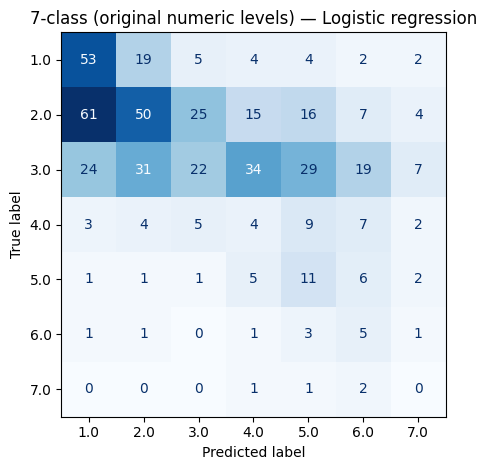


 Random forest | accuracy: 0.447 | balanced accuracy: 0.3 | macro F1: 0.29
              precision    recall  f1-score   support

         1.0       0.52      0.57      0.54        89
         2.0       0.52      0.43      0.47       178
         3.0       0.46      0.54      0.49       166
         4.0       0.23      0.09      0.13        34
         5.0       0.16      0.22      0.19        27
         6.0       0.18      0.25      0.21        12
         7.0       0.00      0.00      0.00         4

    accuracy                           0.45       510
   macro avg       0.29      0.30      0.29       510
weighted avg       0.45      0.45      0.44       510



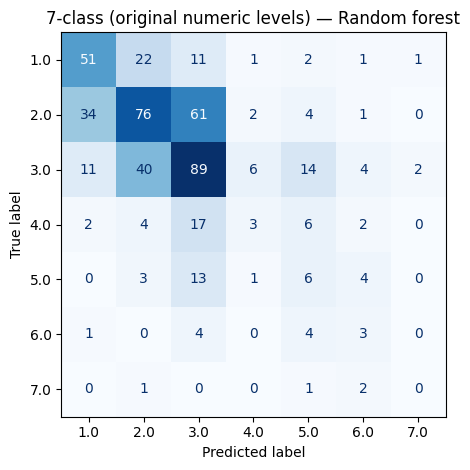


 3-class (1–2 / 3–4 / 5–7)
Class counts: {'1–2': 1068, '3–4': 797, '5–7': 175}

 Logistic regression | accuracy: 0.588 | balanced accuracy: 0.567 | macro F1: 0.514
              precision    recall  f1-score   support

         1–2       0.74      0.73      0.73       267
         3–4       0.57      0.41      0.47       199
         5–7       0.24      0.57      0.33        44

    accuracy                           0.59       510
   macro avg       0.52      0.57      0.51       510
weighted avg       0.63      0.59      0.60       510



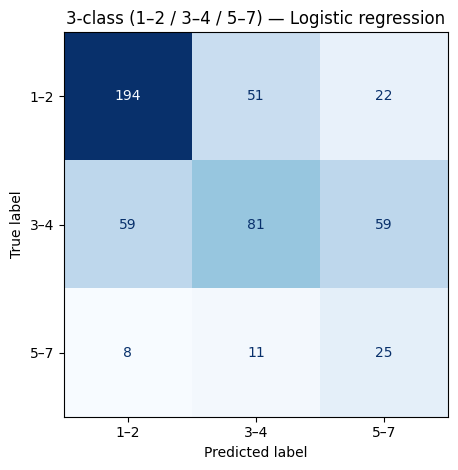


 Random forest | accuracy: 0.625 | balanced accuracy: 0.535 | macro F1: 0.531
              precision    recall  f1-score   support

         1–2       0.74      0.72      0.73       267
         3–4       0.56      0.56      0.56       199
         5–7       0.29      0.32      0.30        44

    accuracy                           0.63       510
   macro avg       0.53      0.53      0.53       510
weighted avg       0.63      0.63      0.63       510



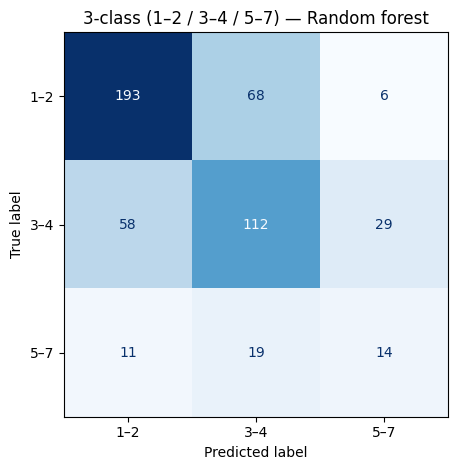


 Binary (1–4 vs 5–7)
Class counts: {0: 1865, 1: 175}

 Logistic regression | accuracy: 0.808 | balanced accuracy: 0.751 | macro F1: 0.633
              precision    recall  f1-score   support

           0       0.96      0.82      0.89       466
           1       0.26      0.68      0.38        44

    accuracy                           0.81       510
   macro avg       0.61      0.75      0.63       510
weighted avg       0.90      0.81      0.84       510



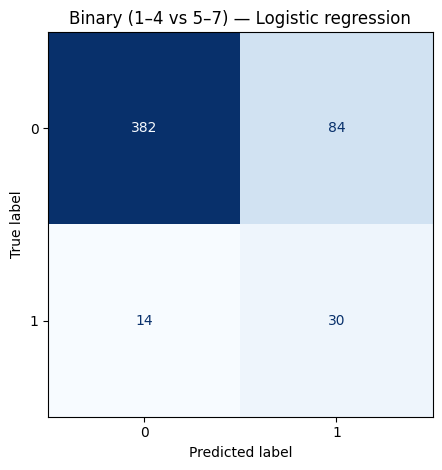


 Random forest | accuracy: 0.904 | balanced accuracy: 0.639 | macro F1: 0.656
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       466
           1       0.42      0.32      0.36        44

    accuracy                           0.90       510
   macro avg       0.68      0.64      0.66       510
weighted avg       0.89      0.90      0.90       510



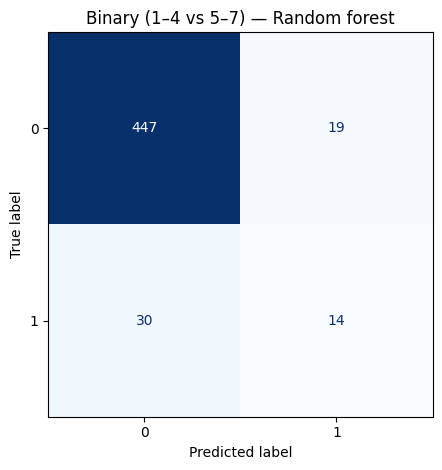

,experiment,model,accuracy,balanced_accuracy,macro_f1,weighted_f1,roc_auc
0,7-class (original numeric levels),Logistic regression,0.284,0.279,0.211,0.288,NaN
1,7-class (original numeric levels),Random forest,0.447,0.300,0.290,0.442,NaN
2,3-class (1–2 / 3–4 / 5–7),Logistic regression,0.588,0.567,0.514,0.598,NaN
3,3-class (1–2 / 3–4 / 5–7),Random forest,0.625,0.535,0.531,0.628,NaN
4,Binary (1–4 vs 5–7),Logistic regression,0.808,0.751,0.633,0.843,0.758
5,Binary (1–4 vs 5–7),Random forest,0.904,0.639,0.656,0.898,0.805


In [44]:
experiments = {
    '7-class (original numeric levels)': df[target],
    '3-class (1–2 / 3–4 / 5–7)': df[target].map(lambda v: '1–2' if v <= 2 else ('3–4' if v <= 4 else '5–7')),
    'Binary (1–4 vs 5–7)': (df[target] >= 5).astype(int)
}
all_results = []
fitted = {}
for experiment, y in experiments.items():
    print('\n' + '='*72 + '\n',experiment)
    print('Class counts:',y.value_counts().sort_index().to_dict())
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,stratify=y,random_state=RANDOM_STATE)
    for model_name, estimator in models().items():
        pipe = Pipeline([('preprocessor',preprocessor()),('model',estimator)])
        pipe.fit(X_train,y_train)
        pred = pipe.predict(X_test)
        row = {'experiment':experiment,'model':model_name,'accuracy':accuracy_score(y_test,pred),
               'balanced_accuracy':balanced_accuracy_score(y_test,pred),
               'macro_f1':f1_score(y_test,pred,average='macro',zero_division=0),
               'weighted_f1':f1_score(y_test,pred,average='weighted',zero_division=0)}
        if y.nunique()==2:
            pos_idx = list(pipe.named_steps['model'].classes_).index(1)
            row['roc_auc'] = roc_auc_score(y_test,pipe.predict_proba(X_test)[:,pos_idx])
        else:
            row['roc_auc'] = np.nan
        all_results.append(row)
        fitted[(experiment,model_name)] = pipe
        print('\n',model_name,'| accuracy:',round(row['accuracy'],3),'| balanced accuracy:',round(row['balanced_accuracy'],3),'| macro F1:',round(row['macro_f1'],3))
        print(classification_report(y_test,pred,zero_division=0))
        ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap='Blues',colorbar=False)
        plt.title(experiment+' — '+model_name)
        plt.tight_layout(); plt.show()
results = pd.DataFrame(all_results)
display(results.round(3))

5. Feature importance (random forest)
These are predictive associations, not evidence of cause and effect. One-hot-encoded categorical variables appear as separate features.


Top 15 features: 7-class (original numeric levels)


,importance
num__actual_job_interesting,0.056938
num__age,0.047882
num__fit_gap_interesting,0.045515
num__fit_gap_income,0.041974
num__career_interest_types_OI_investigative_value,0.040084
num__career_interest_types_OI_social_value,0.038768
num__actual_advancement_high,0.038169
num__career_interest_types_OI_enterprising_value,0.037206
num__actual_job_secure,0.035932
num__career_interest_types_OI_realistic_value,0.032946


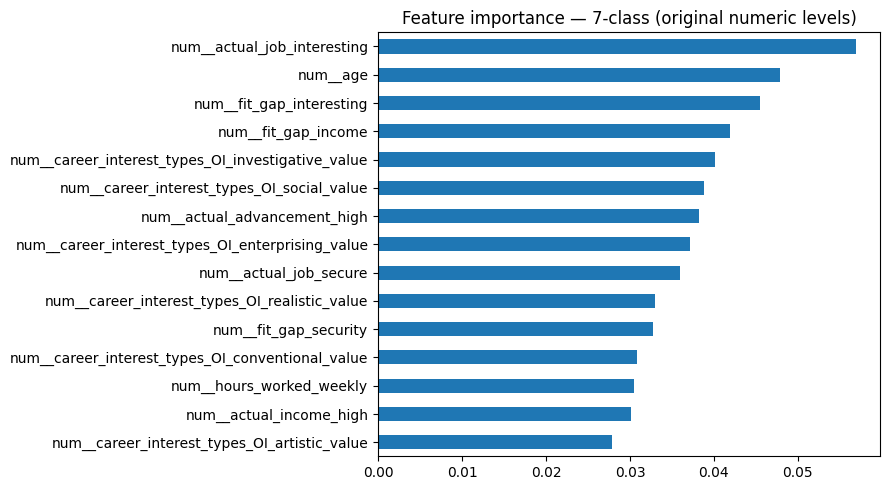


Top 15 features: 3-class (1–2 / 3–4 / 5–7)


,importance
num__actual_job_interesting,0.119746
num__fit_gap_interesting,0.075370
num__actual_advancement_high,0.052376
num__fit_gap_advancement,0.043095
num__actual_job_secure,0.042564
num__actual_income_high,0.037837
num__career_interest_types_OI_investigative_value,0.035287
num__age,0.032175
num__fit_gap_security,0.031727
num__career_interest_types_OI_realistic_value,0.031595


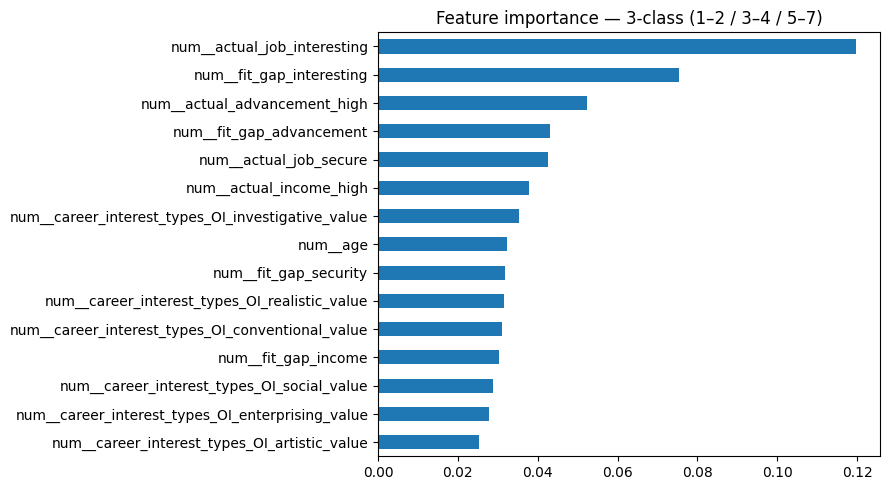


Top 15 features: Binary (1–4 vs 5–7)


,importance
num__actual_job_interesting,0.099663
num__fit_gap_interesting,0.072196
num__actual_income_high,0.054659
num__actual_job_secure,0.054457
num__actual_advancement_high,0.054420
num__fit_gap_advancement,0.043233
num__fit_gap_security,0.042818
num__career_interest_types_OI_conventional_value,0.035630
num__age,0.033988
num__fit_gap_income,0.031901


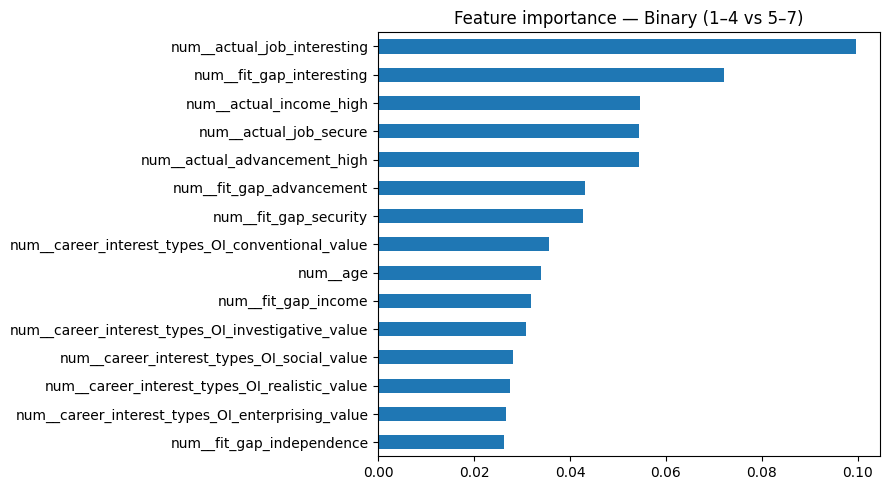

In [45]:
for experiment in experiments:
    pipe = fitted[(experiment,'Random forest')]
    names = pipe.named_steps['preprocessor'].get_feature_names_out()
    importance = pd.Series(pipe.named_steps['model'].feature_importances_,index=names).sort_values(ascending=False).head(15)
    print('\nTop 15 features:',experiment)
    display(importance.rename('importance').to_frame())
    importance.sort_values().plot.barh(figsize=(9,5),title='Feature importance — '+experiment)
    plt.tight_layout();plt.show()

### Baseline Model Findings

We developed baseline machine learning models using a merged ISSP and O*NET dataset containing 2,040 respondents to predict job satisfaction.

Random Forest outperformed Logistic Regression in overall accuracy across the three classification tasks, achieving 44.7% accuracy for seven satisfaction levels, 62.5% for three groups, and 90.4% for binary classification.

Feature importance analysis identified actual job interestingness, the gap between desired and actual job interestingness, income, job security, and advancement opportunities as important predictors.

However, the binary classification results revealed substantial class imbalance. Despite achieving 90.4% accuracy, the Random Forest identified only 32% of respondents in the minority class.

These findings suggest that workplace characteristics contain predictive information about job satisfaction, but further improvements in class balancing, feature engineering, and model evaluation are necessary to develop a reliable prediction model.